Feature names:  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names:  ['setosa' 'versicolor' 'virginica']
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]
4


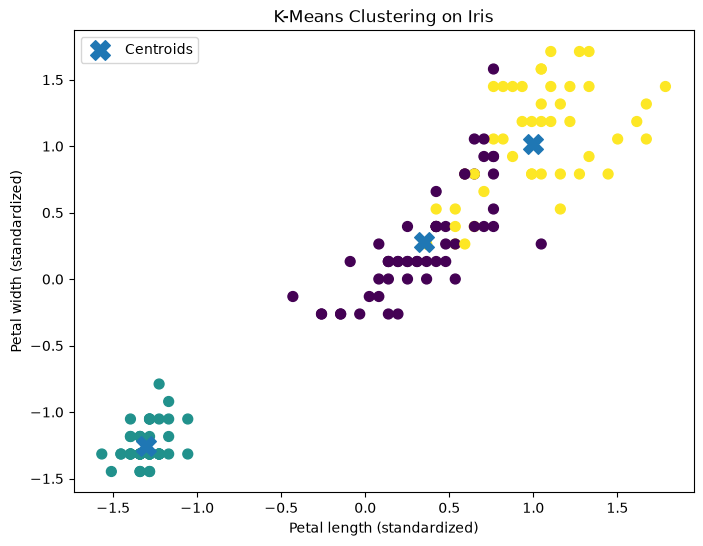

0.45994823920518635


In [ ]:
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from matplotlib import pyplot as plt


iris = load_iris()

X = iris.data
y = iris.target

print("Feature names: ", iris.feature_names)
print("Target names: ", iris.target_names)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=3,
    init="k-means++", # How are clusters initialised
    n_init=10, # Since clustering can lead to different clusters depending on the location of initial clusters 
    #we make many K-Means with different centroid seed and find the best seed that gives the best result
    random_state=42 
)

kmeans.fit(X_scaled)

labels = kmeans.labels_
print(labels)
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3],
    c=labels,
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Petal length (standardized)")
plt.ylabel("Petal width (standardized)")
plt.title("K-Means Clustering on Iris")
plt.legend()

plt.show()


score = silhouette_score(X_scaled, labels) # Measures how well each point was assigned to its cluster
print(score)

